<a href="https://colab.research.google.com/github/Torshaw/Torshaw/blob/main/Dummy%20dAATA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Original Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Date                   210 non-null    datetime64[ns]
 1   Category               210 non-null    object        
 2   Revenue                195 non-null    float64       
 3   Units_Sold             210 non-null    int64         
 4   Customer_Satisfaction  197 non-null    float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(1)
memory usage: 8.3+ KB
None

Number of duplicate rows: 7

--- Cleaned Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
Index: 203 entries, 0 to 209
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Date                   203 non-null    datetime64[ns]
 1   Category               203 

/tmp/ipykernel_7736/1903939362.py:57: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df_cleaned, x='Category', y='Customer_Satisfaction', estimator=np.mean, ci=None, palette='muted', ax=axes[1])
/tmp/ipykernel_7736/1903939362.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_cleaned, x='Category', y='Customer_Satisfaction', estimator=np.mean, ci=None, palette='muted', ax=axes[1])


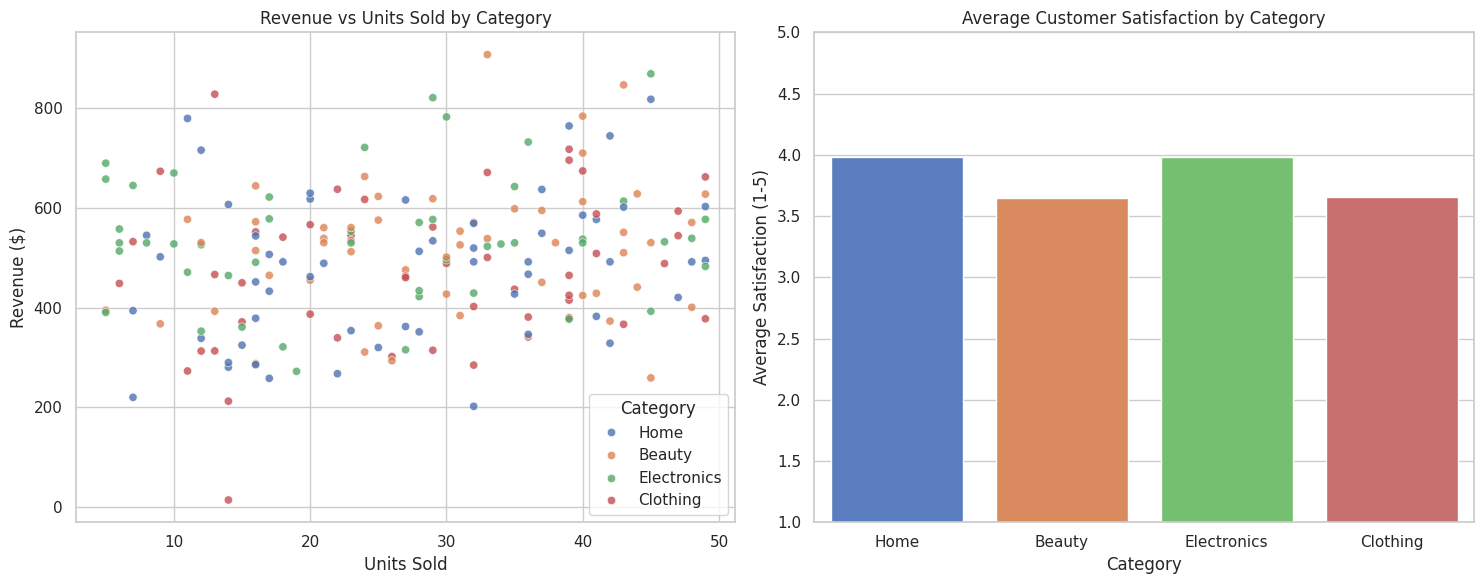

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generate a synthetic dataset
np.random.seed(42)
n_samples = 200

data = {
    'Date': pd.date_range(start='2023-01-01', periods=n_samples, freq='D'),
    'Category': np.random.choice(['Electronics', 'Clothing', 'Home', 'Beauty'], size=n_samples),
    'Revenue': np.random.normal(loc=500, scale=150, size=n_samples),
    'Units_Sold': np.random.randint(5, 50, size=n_samples),
    'Customer_Satisfaction': np.random.choice([1, 2, 3, 4, 5, np.nan], size=n_samples, p=[0.05, 0.1, 0.15, 0.3, 0.35, 0.05])
}

df = pd.DataFrame(data)

# Introduce some duplicates and outliers/nulls for cleaning demonstration
df = pd.concat([df, df.iloc[:10]], ignore_index=True)  # Add duplicates
df.loc[np.random.choice(df.index, 15), 'Revenue'] = np.nan  # Add missing revenues

print("--- Original Dataset Info ---")
print(df.info())
print(f"\nNumber of duplicate rows: {df.duplicated().sum()}")

# 2. Clean the dataset
# Drop exact duplicates
df_cleaned = df.drop_duplicates().copy()

# Fill missing Revenue with the median of its respective Category
df_cleaned['Revenue'] = df_cleaned.groupby('Category')['Revenue'].transform(lambda x: x.fillna(x.median()))

# Fill missing Customer_Satisfaction with the mode of its respective Category
df_cleaned['Customer_Satisfaction'] = df_cleaned.groupby('Category')['Customer_Satisfaction'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 4.0)
)

# Ensure data types are correct
df_cleaned['Customer_Satisfaction'] = df_cleaned['Customer_Satisfaction'].astype(int)

print("\n--- Cleaned Dataset Info ---")
print(df_cleaned.info())

# 3. Visualize the cleaned dataset
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Revenue vs Units Sold by Category
sns.scatterplot(data=df_cleaned, x='Units_Sold', y='Revenue', hue='Category', alpha=0.8, ax=axes[0])
axes[0].set_title('Revenue vs Units Sold by Category')
axes[0].set_xlabel('Units Sold')
axes[0].set_ylabel('Revenue ($)')

# Plot 2: Average Customer Satisfaction by Category
sns.barplot(data=df_cleaned, x='Category', y='Customer_Satisfaction', estimator=np.mean, ci=None, palette='muted', ax=axes[1])
axes[1].set_title('Average Customer Satisfaction by Category')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Average Satisfaction (1-5)')
axes[1].set_ylim(1, 5)

plt.tight_layout()
plt.show()